# 01 - Extract features  (Stage 1)

For every particle in every store: find its first crossing of `C.LAT_CROSS`,
then the first position farther than each radius in `C.RADII_KM` from its own
crossing point (haversine). One row per particle:

* identity: `store`, `row` (position in the store), `traj` (Parcels ID), and a
  running `trajectory_id` added when the parts are combined;
* `release_*`, `cross_time`, `cross_month`, `cross_year`, `cross_lat/lon`,
  `cross_obs`, `days_to_cross`, `r_last_km` (distance at the track's end);
* per radius R: `lat_<R>km`, `lon_<R>km` (the k-means features) and
  `days_<R>km` (days after crossing; NaN if not reached);
* `status`: `complete` (all radii) / `partial` (gate radius reached, last
  position stands in for the missing radii) / `no_gate` / `no_cross`.

**Output:** `data/features_parts/<store>.parquet` (one per store, restartable)
and `data/features.parquet`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [500, 1000, 2000, 3000]


In [2]:
stores = C.list_stores()
print(f"{len(stores)} stores in {C.TRACK_DIRS}")
print("writing per-store parts to:", C.FEATURE_PARTS_DIR)
stores[:3]

1534 stores in ['tracks_v3_11098723', 'tracks_v3_45678', 'tracks_v3_67891', 'tracks_v3_78876']
writing per-store parts to: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius/data/features_parts


[PosixPath('/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_11098723/Parcels_run_11098723_1993-01-06 00:00:00.zarr'),
 PosixPath('/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_11098723/Parcels_run_11098723_1993-01-11 00:00:00.zarr'),
 PosixPath('/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_11098723/Parcels_run_11098723_1993-01-16 00:00:00.zarr')]

## 1.1  Sanity check on one store

In [3]:
df0 = P.extract_store_features(stores[0])
print(df0.status.value_counts().to_string())
# the ID scheme: Parcels IDs have gaps, so traj != row
print("rows 0-4 -> Parcels IDs", df0.traj.head().tolist())
df0.head()

status
partial     8149
complete    1818
no_cross      59
no_gate       35
rows 0-4 -> Parcels IDs [0, 3, 4, 6, 8]


,store,row,traj,release_time,cross_time,cross_obs,cross_lat,cross_lon,days_to_cross,r_last_km,...,lon_2000km,days_2000km,lat_3000km,lon_3000km,days_3000km,release_month,release_year,cross_month,cross_year,status
0,Parcels_run_11098723_1993-01-06 00:00:00,0,0,1993-01-06,1993-04-27 12:00:00,446,2.523308,-50.785912,111.50,426.539948,...,NaN,NaN,NaN,NaN,NaN,1,1993,4,1993,no_gate
1,Parcels_run_11098723_1993-01-06 00:00:00,1,3,1993-01-06,1993-04-17 06:00:00,405,2.509987,-50.418179,101.25,1966.210083,...,-57.482864,NaN,18.783516,-57.482864,NaN,1,1993,4,1993,partial
2,Parcels_run_11098723_1993-01-06 00:00:00,2,4,1993-01-06,1993-06-01 06:00:00,585,2.513855,-49.882217,146.25,1339.147827,...,-56.286156,NaN,12.754312,-56.286156,NaN,1,1993,6,1993,partial
3,Parcels_run_11098723_1993-01-06 00:00:00,3,6,1993-01-06,1993-03-24 18:00:00,311,2.523104,-49.830769,77.75,2820.306885,...,-64.715714,51.25,19.118475,-69.438858,NaN,1,1993,3,1993,partial
4,Parcels_run_11098723_1993-01-06 00:00:00,4,8,1993-01-06,1993-01-26 12:00:00,82,2.519889,-50.214470,20.50,2326.062012,...,-63.743439,90.00,18.102886,-64.449043,NaN,1,1993,1,1993,partial


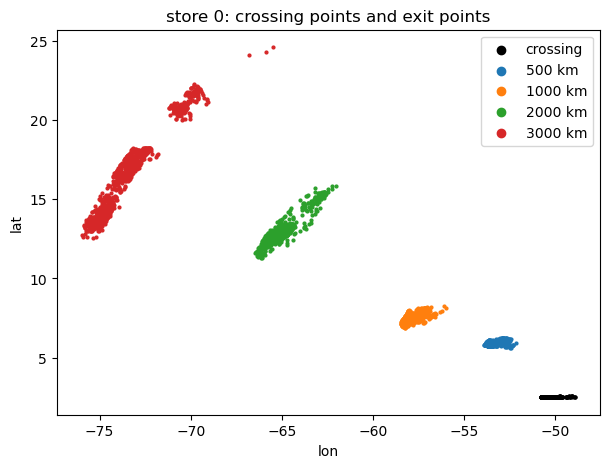

In [4]:
import matplotlib.pyplot as plt
sub = df0[df0.status == "complete"].head(1000)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sub.cross_lon, sub.cross_lat, s=4, c="k", label="crossing")
for r in C.RADII_KM:
    ax.scatter(sub[P.lon_col(r)], sub[P.lat_col(r)], s=4, label=f"{r} km")
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.legend(markerscale=3)
ax.set_title("store 0: crossing points and exit points")
plt.show()

## 1.2  All stores (parallel, one process per store)

Parts are named after the store, so re-running only fills the gaps, and a part
always belongs to the store it is named after. `N_JOBS` defaults to
`$SLURM_CPUS_PER_TASK`.

In [5]:
from joblib import Parallel, delayed

N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", 8))

def _extract_one(s):
    part = C.FEATURE_PARTS_DIR / f"{s.stem}.parquet"
    if part.exists():
        return None
    P.extract_store_features(s).to_parquet(part, index=False)
    return s.stem

print(f"extracting {len(stores)} stores with n_jobs={N_JOBS} ...")
Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(delayed(_extract_one)(s) for s in stores)

extracting 1534 stores with n_jobs=8 ...


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    4.6s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    6.3s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    6.6s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    9.3s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:   11.4s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:   13.4s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:   15.3s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:   18.5s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:   21.0s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:   24.5s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:   27.7s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:   31.0s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:   35.1s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:   39.1s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:   43.2s
[Parallel(

['Parcels_run_11098723_1993-01-06 00:00:00',
 'Parcels_run_11098723_1993-01-11 00:00:00',
 'Parcels_run_11098723_1993-01-16 00:00:00',
 'Parcels_run_11098723_1993-01-21 00:00:00',
 'Parcels_run_11098723_1993-01-26 00:00:00',
 'Parcels_run_11098723_1993-01-31 00:00:00',
 'Parcels_run_11098723_1993-02-05 00:00:00',
 'Parcels_run_11098723_1993-02-10 00:00:00',
 'Parcels_run_11098723_1993-02-15 00:00:00',
 'Parcels_run_11098723_1993-02-20 00:00:00',
 'Parcels_run_11098723_1993-02-25 00:00:00',
 'Parcels_run_11098723_1993-03-02 00:00:00',
 'Parcels_run_11098723_1993-03-07 00:00:00',
 'Parcels_run_11098723_1993-03-12 00:00:00',
 'Parcels_run_11098723_1993-03-17 00:00:00',
 'Parcels_run_11098723_1993-03-22 00:00:00',
 'Parcels_run_11098723_1993-03-27 00:00:00',
 'Parcels_run_11098723_1993-04-01 00:00:00',
 'Parcels_run_11098723_1993-04-06 00:00:00',
 'Parcels_run_11098723_1993-04-11 00:00:00',
 'Parcels_run_11098723_1993-04-16 00:00:00',
 'Parcels_run_11098723_1993-04-21 00:00:00',
 'Parcels_

## 1.3  Combine into `features.parquet`

Only parts of stores that are currently in `C.list_stores()` are used. The
running `trajectory_id` is assigned here; it is a row number for joins and
nothing is decoded from it.

In [6]:
names = [s.stem for s in stores]
parts = [C.FEATURE_PARTS_DIR / f"{n}.parquet" for n in names]
missing = [p.name for p in parts if not p.exists()]
assert not missing, f"{len(missing)} stores not extracted yet, e.g. {missing[:3]}"
stale = sorted(set(p.stem for p in C.FEATURE_PARTS_DIR.glob("*.parquet")) - set(names))
if stale:
    print(f"ignoring {len(stale)} parts of stores no longer listed, e.g. {stale[:3]}")

features = pd.concat((pd.read_parquet(p) for p in parts), ignore_index=True)
features["store"] = features["store"].astype("category")
features.insert(0, "trajectory_id", np.arange(len(features), dtype=np.int64))
assert not features.duplicated(["store", "traj"]).any(), "duplicate (store, traj)"
features.to_parquet(C.FEATURES_FILE, index=False)
print("combined shape:", features.shape, "->", C.FEATURES_FILE)

combined shape: (15485167, 28) -> /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius/data/features.parquet


## 1.4  Summary

In [7]:
n = len(features)
print(f"{n:,} particles from {features.store.nunique()} stores")
for k, v in features.status.value_counts().reindex(P.STATUSES).items():
    print(f"  {k:9s}: {v:12,}  ({100*v/n:5.2f}%)")
cr = features[features.status != "no_cross"]
print(f"\ndays release -> crossing: median {cr.days_to_cross.median():.1f}, "
      f"5-95%: {cr.days_to_cross.quantile(.05):.1f}-{cr.days_to_cross.quantile(.95):.1f}")
print("\nper radius, among crossing particles:")
for r in C.RADII_KM:
    d = cr[P.days_col(r)]
    print(f"  {r:5d} km: reached {100*d.notna().mean():5.1f}%   "
          f"median {d.median():5.1f} d after crossing")
print(f"\nrelease years {features.release_year.min()}-{features.release_year.max()}")

15,485,167 particles from 1534 stores
  complete :    3,272,735  (21.13%)
  partial  :   11,733,866  (75.77%)
  no_gate  :      122,025  ( 0.79%)
  no_cross :      356,541  ( 2.30%)

days release -> crossing: median 32.8, 5-95%: 9.0-121.8

per radius, among crossing particles:
    500 km: reached  99.2%   median  13.8 d after crossing
   1000 km: reached  97.7%   median  29.2 d after crossing
   2000 km: reached  75.2%   median  72.5 d after crossing
   3000 km: reached  21.6%   median 119.5 d after crossing

release years 1993-2013
